# From polymer graphs to linear viscoelasticity
### A guided Python case study for first-year engineering students

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 20 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/20_Polymer_Graphs_and_Viscoelasticity.ipynb)

**Question.** If two polymer molecules have the same seven beads and the same spring stiffness, can their connections alone change how quickly they relax? In a simplified bead-and-spring model, **yes**. A chain, ring, and branched star have different connectivity matrices and spectra of internal relaxation modes. We will construct the graphs, solve small eigenvalue problems, simulate recovery from a small displacement, and then connect those modes to idealized shear relaxation and oscillatory viscoelasticity.

The main route is written for self-study: it uses lists, loops, arrays, functions, figures, and numerical checks. The viscoelastic modulus and an edge-space cycle calculation are marked **optional** because they need additional physics or linear algebra. Every executable line has an adjacent explanatory comment. Run cells **in order** in JupyterLab or Jupyter Notebook; the only external packages are NumPy and Matplotlib (`python -m pip install numpy matplotlib` if needed). No files, random input, NetworkX, or SciPy are needed.

**Physical scope.** The molecular examples are connected Gaussian bead-spring structures with equal Hookean spring constant $k$ and equal isotropic bead friction $\zeta$, subject to overdamped, free-draining dynamics. The deterministic displacement calculation shows the decay of a small mean disturbance; the later stress relaxation formula requires an equilibrium thermal ensemble and a small imposed shear. We neglect hydrodynamic interactions, excluded volume, entanglement, finite extensibility, crosslink kinetics, and solvent contributions to stress. The calculations demonstrate consequences of this model, not quantitative predictions for an arbitrary real polymer.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Optional · Extensions |
| **Time** | about 45 min of reading |
| **Before this** | Notebook 17 (linear algebra). |
| **Essential** | Sections 1–4 and 7. |
| **Optional on a first reading** | Sections 5 and 6 (rheology and edge-space graph theory). |
| **Next** | Any other extension. |

**You have understood this notebook if you can, without looking back:**

1. Build a Laplacian matrix from an edge list, and check that each row sums to zero.
2. Explain what the zero eigenvalue means, and why the smallest non-zero one sets the slowest relaxation.
3. Predict how adding or removing one bond changes the slowest mode, then check.
4. Compare the exact mode solution with an Euler loop, and explain how the step size matters.

**Not expected of you:** The rheology formulas and the graph theory in Sections 5–6.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## Learning map and connections to earlier notebooks

| Step | Python skill | Mathematical or physical idea |
|:--|:--|:--|
| Draw three molecular architectures | Lists of edges, dictionaries, `for` loops | Beads as vertices and springs as edges |
| Build graph matrices | Indexing, 2D arrays, functions | Adjacency $A$, degree $D$, Laplacian $L=D-A$ |
| Find normal modes | `numpy.linalg.eigh`, sorting, assertions | Translation and internal eigenmodes |
| Evolve a displacement | Loops, time arrays, Euler iteration | Relaxation rate and numerical error |
| Optional shear response | Vectorized functions, log plots | Relaxation modulus, storage and loss moduli |
| Optional edge-space matrix | Matrix products, zero modes | A ring's independent cycle constraint |

The graph Laplacian material extends our linear-algebra case study; the overdamped bead motion relates to our molecular-dynamics case studies. Here we use **dimensionless time** $t^*=kt/\zeta$. An internal **coordinate** mode of eigenvalue $\lambda_p$ decays as $e^{-\lambda_p t^*}$. The center-of-mass translation has $\lambda_0=0$ and does not relax by spring forces alone. Later, the idealized **shear-stress** mode decays as $e^{-2\lambda_p t^*}$; a stress relaxation time is half the corresponding coordinate relaxation time. Keeping these observables distinct is essential.

**Source orientation.** Yang and Yu's 1984 paper treats linear and cyclic chains, their 1985 paper extends graph methods to star-shaped and more complex molecules, and Yang's 1998 feature article connects graph spectra to viscoelastic and configurational properties. We implement a small numerical Laplacian example rather than reproduce their more advanced graphical characteristic-polynomial proofs. Their notation and bead counts differ across papers; here $N$ always means **number of beads**, and $m$ means **number of springs**.

## 1. Represent three seven-bead molecules as graphs

A **vertex** represents a bead; an undirected **edge** represents an identical spring connecting two different beads. We label beads 0 through 6. A chain has six edges, and a ring has its six chain edges **plus a closing edge** between 6 and 0. The three-arm star has a central bead 0, with three arms of two edges each, also six edges. Thus the chain and star have the same bead and edge counts but different connectivity. The ring has one extra spring: when comparing it with the chain, describe the change as *adding a bond*, not as changing topology at fixed bond count.

The drawn coordinates are schematic and do **not** represent actual equilibrium polymer conformations or spring lengths. In the Gaussian model the configurations fluctuate thermally; the graph specifies only which beads are linked.

In [1]:
# Import NumPy for matrices, eigenvalues, and vectorized relaxation calculations.
import numpy as np
# Import pyplot for graph drawings and time- and frequency-domain figures.
import matplotlib.pyplot as plt
# Choose a readable default figure size for embedded self-study plots.
plt.rcParams['figure.figsize'] = (8, 4.5)
# Use a common number of beads so all three Laplacians have the same dimensions.
bead_count = 7
# Connect each consecutive pair of beads to form a linear chain.
chain_edges = [(index, index + 1) for index in range(bead_count - 1)]
# Add one closing spring between the last and first bead to form a ring.
ring_edges = chain_edges + [(bead_count - 1, 0)]
# Connect three two-bond arms to a common bead 0 to form a branched star.
star_edges = [(0, 1), (1, 2), (0, 3), (3, 4), (0, 5), (5, 6)]
# Store all edge lists under concise names for reuse throughout the notebook.
graphs = {'Chain': chain_edges, 'Ring': ring_edges, 'Three-arm star': star_edges}
# Set schematic coordinates for the straight chain in the first drawing.
chain_positions = {index: (index, 0.0) for index in range(bead_count)}
# Place ring beads on a circle without assigning physical spring lengths.
ring_positions = {index: (np.cos(2.0 * np.pi * index / bead_count), np.sin(2.0 * np.pi * index / bead_count)) for index in range(bead_count)}
# Place the central star bead at the origin and two beads on each radial arm.
star_positions = {0: (0.0, 0.0), 1: (1.0, 0.0), 2: (2.0, 0.0), 3: (-0.5, 0.87), 4: (-1.0, 1.74), 5: (-0.5, -0.87), 6: (-1.0, -1.74)}
# Associate each topology with the positions used only in its own diagram.
positions = {'Chain': chain_positions, 'Ring': ring_positions, 'Three-arm star': star_positions}
# Report bead count and spring count before discussing differences in spectra.
for name, edges in graphs.items():
    # Print an interpretable summary of the graph's two basic sizes.
    print(f'{name}: {bead_count} beads, {len(edges)} springs; edges={edges}')

Chain: 7 beads, 6 springs; edges=[(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6)]
Ring: 7 beads, 7 springs; edges=[(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 0)]
Three-arm star: 7 beads, 6 springs; edges=[(0, 1), (1, 2), (0, 3), (3, 4), (0, 5), (5, 6)]


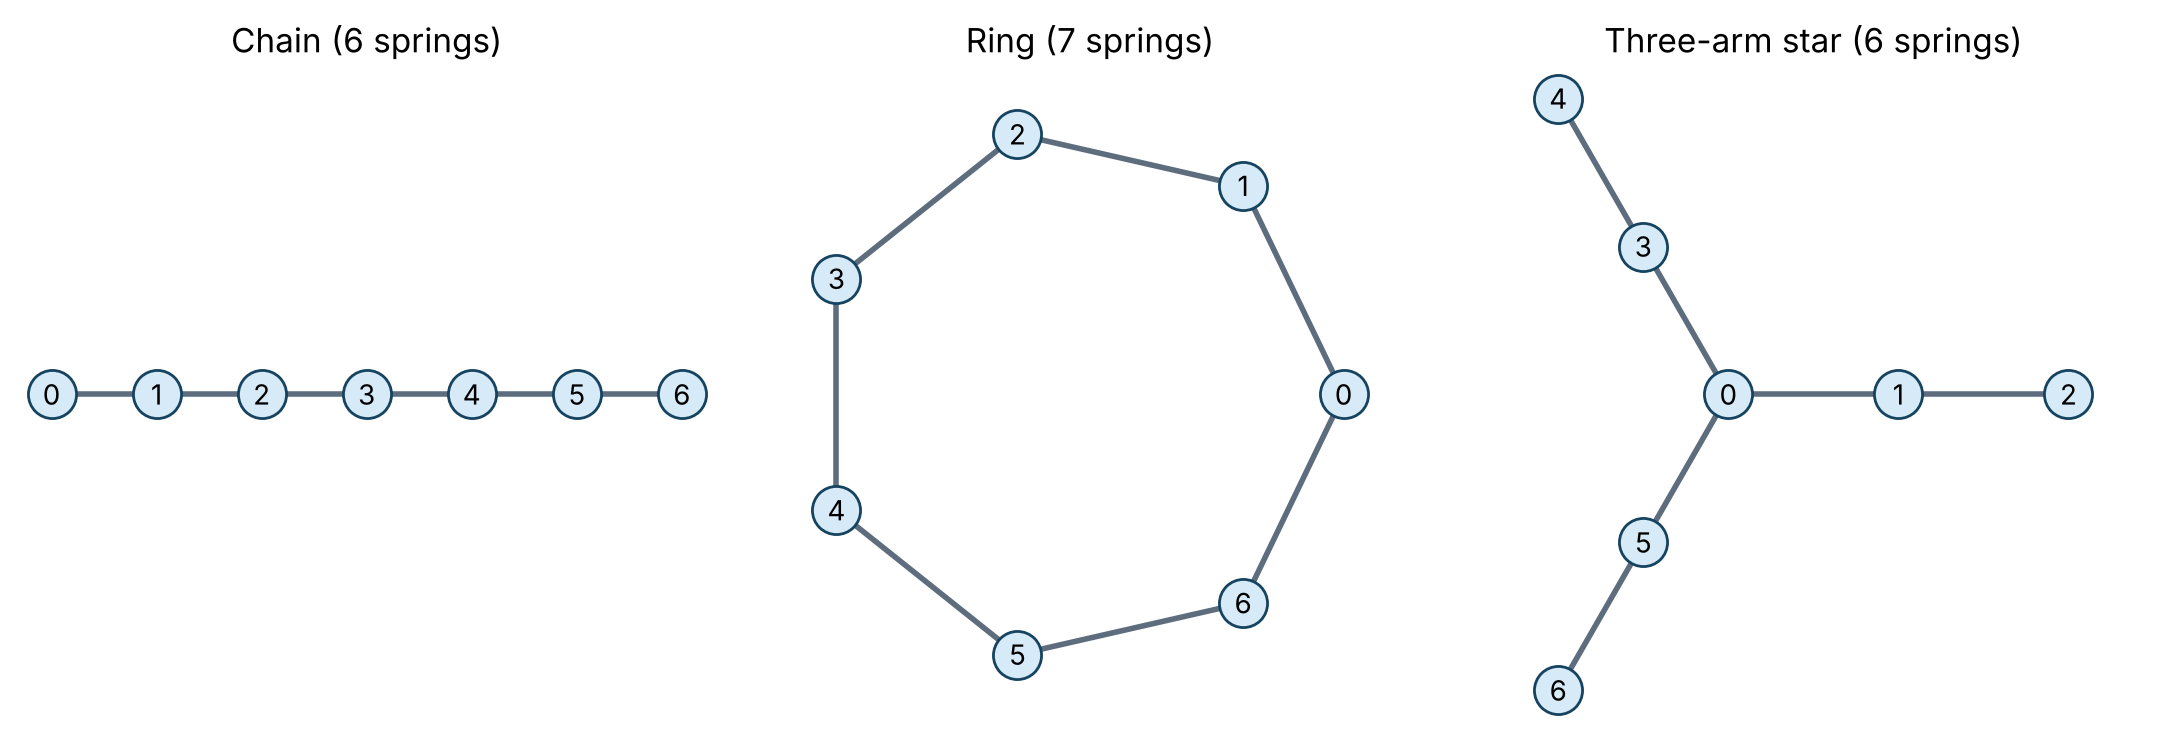

In [2]:
# Create one panel per graph to compare topology on a common page.
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
# Draw each named architecture in its corresponding panel.
for ax, (name, edges) in zip(axes, graphs.items()):
    # Retrieve the schematic bead positions for this architecture.
    diagram = positions[name]
    # Draw every spring as a line between its two endpoint beads.
    for first, second in edges:
        # Extract the two horizontal drawing coordinates in edge order.
        xs = [diagram[first][0], diagram[second][0]]
        # Extract the corresponding vertical drawing coordinates.
        ys = [diagram[first][1], diagram[second][1]]
        # Plot one visible spring behind the bead labels.
        ax.plot(xs, ys, color='#5D6D7E', linewidth=2, zorder=1)
    # Visit every bead label, including the common branch point of the star.
    for bead, (x, y) in diagram.items():
        # Mark the bead with a circle that remains visible against the spring.
        ax.scatter(x, y, s=300, color='#D6EAF8', edgecolor='#154360', zorder=2)
        # Place its integer identifier inside the circle.
        ax.text(x, y, str(bead), ha='center', va='center', zorder=3)
    # Name the topology and number of springs rather than implying geometric length.
    ax.set_title(f'{name} ({len(edges)} springs)')
    # Preserve the drawn geometry within each panel.
    ax.set_aspect('equal', adjustable='datalim')
    # Hide axes because the graph coordinates carry no physical units.
    ax.axis('off')
# Prevent title collisions between neighbouring panels.
fig.tight_layout()
# Display the three molecular connectivity patterns side by side.
plt.show()

## 2. Turn an edge list into a Laplacian matrix

For a simple undirected graph, $A_{ij}=1$ if beads $i$ and $j$ share a spring and zero otherwise; $D_{ii}$ equals the number of springs touching bead $i$. The **node Laplacian** is $L=D-A$. Its diagonal entries are bead degrees, its connected off-diagonal entries are $-1$, and every row sums to zero. Since the springs resist bead differences, not uniform translation, $L\mathbf 1=0$.

It is also useful to choose an **arbitrary reference direction** for each spring and build the incidence matrix $B$: one $+1$ at its first endpoint and one $-1$ at its second endpoint. Then $L=BB^\mathsf T$. Reversing an edge's reference direction flips one column of $B$, but leaves $BB^\mathsf T$ unchanged. For any displacement vector $u$, $u^\mathsf TLu=\sum_{(i,j)}(u_i-u_j)^2\geq0$; thus no Laplacian eigenvalue should be meaningfully negative. The graph is undirected physically despite our bookkeeping choice for $B$.

In [3]:
# Define a matrix builder that returns adjacency, degree, incidence, and Laplacian.
def graph_matrices(number_of_beads, edges):
    # Document the order and shape of all four returned objects.
    """Return (A, D, B, L) for a simple undirected bead-spring graph."""
    # Check that the requested graph has a positive integer bead count.
    if isinstance(number_of_beads, bool) or not isinstance(number_of_beads, int) or number_of_beads < 1:
        # Explain the required node labels 0 through number_of_beads-1.
        raise ValueError('number_of_beads must be a positive integer')
    # Start an empty symmetric bead-to-bead adjacency matrix.
    adjacency = np.zeros((number_of_beads, number_of_beads), dtype=float)
    # Start an incidence matrix with one column for each spring.
    incidence = np.zeros((number_of_beads, len(edges)), dtype=float)
    # Store seen undirected pairs so duplicate springs cannot slip into the simple graph.
    seen_edges = set()
    # Visit each supplied edge while retaining its assigned incidence-column direction.
    for column, (first, second) in enumerate(edges):
        # Reject out-of-range, non-integer, and self-connected bead identifiers.
        if isinstance(first, bool) or isinstance(second, bool) or not isinstance(first, int) or not isinstance(second, int) or not (0 <= first < number_of_beads and 0 <= second < number_of_beads) or first == second:
            # Identify malformed spring endpoints before array indexing.
            raise ValueError('each edge must join two different valid bead indices')
        # Create an order-independent key for detecting a repeated spring.
        key = tuple(sorted((first, second)))
        # Check for a duplicate undirected connection.
        if key in seen_edges:
            # Avoid counting the same simple-graph spring twice.
            raise ValueError('duplicate edge in a simple graph')
        # Remember this edge before reading the next spring.
        seen_edges.add(key)
        # Mark both symmetric adjacency entries for an undirected spring.
        adjacency[first, second] = adjacency[second, first] = 1.0
        # Assign a positive incidence sign at the first listed bead.
        incidence[first, column] = 1.0
        # Assign a negative sign at the second listed bead.
        incidence[second, column] = -1.0
    # Put the number of incident springs on each diagonal degree entry.
    degree = np.diag(adjacency.sum(axis=1))
    # Subtract adjacency from degree to form the node Laplacian.
    laplacian = degree - adjacency
    # Return every matrix so its role can be inspected independently.
    return adjacency, degree, incidence, laplacian

# Build and store all matrices for each of the three small architectures.
matrices = {name: graph_matrices(bead_count, edges) for name, edges in graphs.items()}
# Extract the chain's matrices to demonstrate the computation concretely.
chain_A, chain_D, chain_B, chain_L = matrices['Chain']
# Show adjacency for the chain in the shared bead order 0 through 6.
print('Chain adjacency A:\n', chain_A.astype(int))
# Show how degree and adjacency combine to form the Laplacian.
print('Chain Laplacian L=D-A:\n', chain_L.astype(int))
# Verify the factorization of the same chain graph via its signed incidence matrix.
assert np.allclose(chain_L, chain_B @ chain_B.T)
# Check that a uniform bead translation produces zero spring force.
assert np.allclose(chain_L @ np.ones(bead_count), 0.0)

Chain adjacency A:
 [[0 1 0 0 0 0 0]
 [1 0 1 0 0 0 0]
 [0 1 0 1 0 0 0]
 [0 0 1 0 1 0 0]
 [0 0 0 1 0 1 0]
 [0 0 0 0 1 0 1]
 [0 0 0 0 0 1 0]]
Chain Laplacian L=D-A:
 [[ 1 -1  0  0  0  0  0]
 [-1  2 -1  0  0  0  0]
 [ 0 -1  2 -1  0  0  0]
 [ 0  0 -1  2 -1  0  0]
 [ 0  0  0 -1  2 -1  0]
 [ 0  0  0  0 -1  2 -1]
 [ 0  0  0  0  0 -1  1]]


### Checks for any connected bead-spring graph

The Laplacian is symmetric and positive semidefinite. Its number of zero eigenvalues equals the number of connected components. Each of our molecules is connected, so it should have **one** zero eigenvalue: the collective translation. A ring has a closed cycle, but it still has only one zero eigenvalue in the **node** Laplacian. Later we will see why an **edge-space** matrix has an additional cycle-related zero direction for the ring; the two zero directions have different physical meanings.

In [4]:
# Prepare a dictionary for each graph's ordered eigenvalues and eigenvectors.
spectra = {}
# Visit each topology to verify its matrices and compute its normal modes.
for name, (adjacency, degree, incidence, laplacian) in matrices.items():
    # Use the symmetric-matrix eigensolver, which returns real ordered eigenvalues.
    eigenvalues, eigenvectors = np.linalg.eigh(laplacian)
    # Store the complete spectrum, including the one translation eigenvalue.
    spectra[name] = (eigenvalues, eigenvectors)
    # Display the seven eigenvalues without interpreting rounding as exact equality.
    print(f'{name:15s}: {np.round(eigenvalues, 6)}')
    # Check algebraically that the edge orientation does not alter the node Laplacian.
    assert np.allclose(laplacian, incidence @ incidence.T)
    # Check symmetry and the exact row-sum property up to floating-point tolerance.
    assert np.allclose(laplacian, laplacian.T) and np.allclose(laplacian.sum(axis=1), 0.0)
    # Confirm one numerical zero and strictly positive internal modes.
    assert abs(eigenvalues[0]) < 1e-12 and np.all(eigenvalues[1:] > 1e-10)
    # Reconstruct the matrix from its numerical eigenpairs as an independent check.
    assert np.allclose(laplacian, eigenvectors @ np.diag(eigenvalues) @ eigenvectors.T)
# Calculate the positive-semidefinite quadratic form for a sample displacement.
example_displacement = np.array([1.0, 0.0, -0.5, 0.2, -0.2, 0.4, -0.9])
# Evaluate the chain energy-like sum directly from spring differences.
sum_of_squares = sum((example_displacement[i] - example_displacement[j])**2 for i, j in chain_edges)
# Evaluate the equivalent matrix quadratic form using the chain Laplacian.
quadratic_form = example_displacement @ chain_L @ example_displacement
# Print both methods so the graph-matrix identity is testable.
print(f'Chain sum of spring differences squared={sum_of_squares:.6f}; u^T L u={quadratic_form:.6f}')
# Confirm both nonnegative calculations agree despite different code paths.
assert np.isclose(sum_of_squares, quadratic_form) and quadratic_form >= 0.0

Chain          : [0.       0.198062 0.75302  1.554958 2.445042 3.24698  3.801938]
Ring           : [-0.        0.75302   0.75302   2.445042  2.445042  3.801938  3.801938]
Three-arm star : [0.       0.381966 0.381966 1.585786 2.618034 2.618034 4.414214]
Chain sum of spring differences squared=3.950000; u^T L u=3.950000


## 3. What do the eigenvalues mean?

With a scalar coordinate $u_i$ for the displacement of each bead and identical spring constant $k$, the energy for this *one coordinate* is $U=(k/2)\sum_{(i,j)}(u_i-u_j)^2=(k/2)u^\mathsf TLu$. In the **deterministic part** of overdamped Rouse dynamics,

$$\zeta\frac{du}{dt}=-kLu,\qquad t^*=kt/\zeta,\qquad \frac{du}{dt^*}=-Lu.$$

For an eigenvector $v_p$ with $Lv_p=\lambda_pv_p$, its amplitude obeys $a_p(t^*)=a_p(0)e^{-\lambda_pt^*}$. The internal coordinate relaxation time is therefore $\tau_p^{\rm coord}/(\zeta/k)=1/\lambda_p$. A smaller positive eigenvalue means a slower internal coordinate mode. A zero eigenvalue describes uniform translation; it is excluded when discussing internal recovery.

For a seven-bead **chain**, the exact eigenvalues are $2[1-\cos(p\pi/N)]$ with $p=0,\ldots,N-1$. For a seven-bead **ring**, they are $2[1-\cos(2p\pi/N)]$. The ring values occur in equal pairs because modes travelling clockwise and counterclockwise share a rate. Numerical eigenvectors in a degenerate subspace can rotate or change sign, so compare **eigenvalues and subspaces**, not individual vector entries, across runs.

In [5]:
# Label the theoretical mode numbers for our seven-bead chain and ring.
mode_numbers = np.arange(bead_count)
# Evaluate the exact open-chain eigenvalue formula in its increasing order.
chain_theory = 2.0 * (1.0 - np.cos(np.pi * mode_numbers / bead_count))
# Evaluate the periodic-ring formula and sort its paired eigenvalues.
ring_theory = np.sort(2.0 * (1.0 - np.cos(2.0 * np.pi * mode_numbers / bead_count)))
# Compare the direct chain diagonalization with its known closed form.
assert np.allclose(spectra['Chain'][0], chain_theory, atol=1e-12)
# Compare the ring diagonalization with its independent trigonometric prediction.
assert np.allclose(spectra['Ring'][0], ring_theory, atol=1e-12)
# Display the slowest positive eigenvalue and its dimensionless coordinate time.
for name, (eigenvalues, eigenvectors) in spectra.items():
    # Keep the first eigenvalue, which is translation, out of internal relaxation.
    slowest = eigenvalues[1]
    # Print both the rate and its reciprocal in units of zeta/k.
    print(f'{name:15s}: lambda_1={slowest:.6f}, slowest coordinate time*={1.0/slowest:.6f}')

Chain          : lambda_1=0.198062, slowest coordinate time*=5.048917
Ring           : lambda_1=0.753020, slowest coordinate time*=1.327985
Three-arm star : lambda_1=0.381966, slowest coordinate time*=2.618034


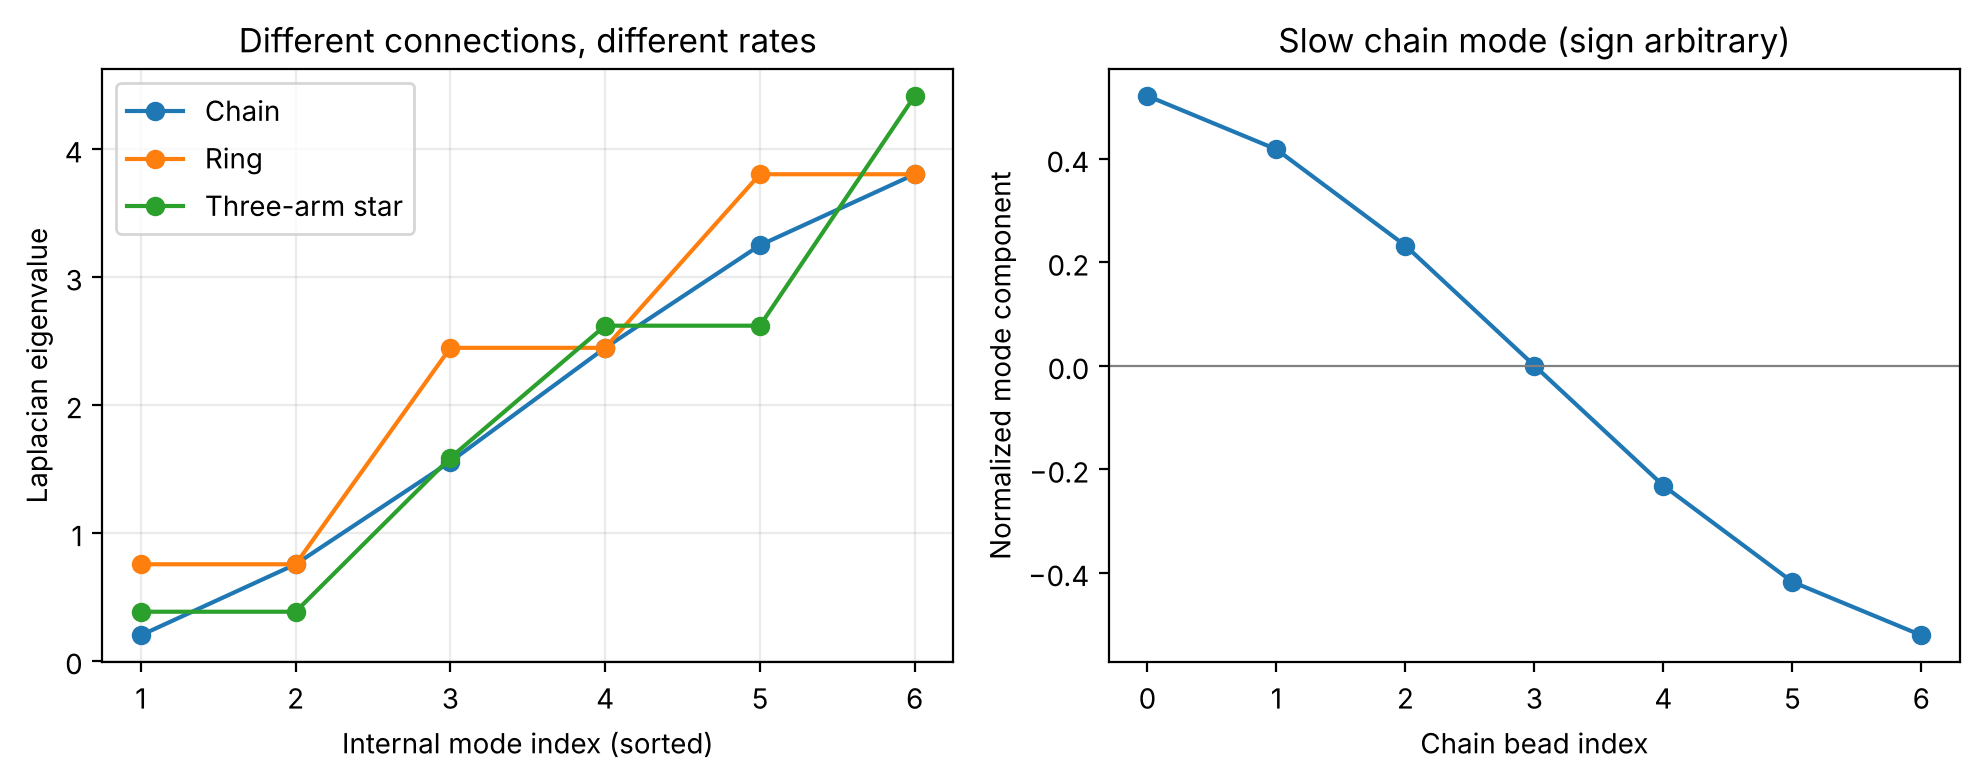

In [6]:
# Open panels for the eigenvalue spectrum and one unambiguous chain mode.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# Visit the three spectra to compare their six positive internal eigenvalues.
for name, (eigenvalues, eigenvectors) in spectra.items():
    # Place modes 1 through 6 on the same numerical mode index axis.
    axes[0].plot(np.arange(1, bead_count), eigenvalues[1:], marker='o', label=name)
# Identify the zero translation mode as deliberately omitted from this panel.
axes[0].set(xlabel='Internal mode index (sorted)', ylabel='Laplacian eigenvalue', title='Different connections, different rates')
# Distinguish chain, ring, and star in the spectrum plot.
axes[0].legend()
# Add a light visual guide without hiding close values.
axes[0].grid(alpha=0.25)
# Extract the slowest chain internal eigenvector for a shape illustration.
slow_chain_vector = spectra['Chain'][1][:, 1]
# Plot its component at each bead, with arbitrary eigenvector sign.
axes[1].plot(np.arange(bead_count), slow_chain_vector, marker='o')
# State that vector amplitude and sign have no unique physical normalization here.
axes[1].set(xlabel='Chain bead index', ylabel='Normalized mode component', title='Slow chain mode (sign arbitrary)')
# Draw a zero reference line to distinguish opposite bead movements.
axes[1].axhline(0.0, color='gray', linewidth=0.8)
# Keep bead indices and figure labels readable.
fig.tight_layout()
# Display topology-dependent normal modes and a representative eigenvector.
plt.show()

### Focused experiment: what does one changed connection do?

The figures compare three architectures, but we can sharpen the central question with **two controlled changes** to the same seven-bead chain.

1. **Add one bond:** connect bead 6 to bead 0. This makes the ring. The number of beads stays 7, while the spring count rises from 6 to 7. If $b$ is the incidence column of that added bond, $L_{\rm ring}=L_{\rm chain}+bb^\mathsf T$. We expect a different spectrum, and we can check the slowest internal coordinate time $\tau_1^*=1/\lambda_1$ directly. Adding a positive spring makes the Laplacian quadratic form larger or equal for every displacement; in this example, the ordered eigenvalues do not decrease.
2. **Move one bond:** remove the chain's $(3,4)$ bond and connect $(1,4)$ instead. This keeps **seven beads and six identical springs**, remains connected, and makes bead 1 a branch point of degree 3. It is a different branched tree from the symmetric three-arm star in the opening figure. The rewiring changes the graph by both a removal and an addition, so the simple monotonicity claim for *adding* a bond does not apply.

We will print all nonzero eigenvalues and the slowest time before and after each change. This is a statement about our equal-$k$, equal-$\zeta$ model. An individual deterministic displacement may relax at a different apparent rate depending on which modes it excites.

In [7]:
# Recover the already calculated chain and ring Laplacians from our graph dictionary.
base_laplacian = matrices['Chain'][3]
# Read the ring Laplacian independently from its complete edge list.
closed_laplacian = matrices['Ring'][3]
# Build the incidence column for the single added closing bond, from bead 6 to bead 0.
closing_column = np.zeros(bead_count)
# Put a positive sign at the first endpoint of the chosen reference direction.
closing_column[6] = 1.0
# Put a negative sign at the second endpoint of that same spring.
closing_column[0] = -1.0
# Check the exact rank-one change in the node Laplacian caused by one bond.
assert np.allclose(closed_laplacian - base_laplacian, np.outer(closing_column, closing_column))
# Remove precisely the chain spring between beads 3 and 4.
rewired_edges = [edge for edge in chain_edges if edge != (3, 4)]
# Attach bead 4 to bead 1, creating a three-way junction while retaining six springs.
rewired_edges.append((1, 4))
# Build all matrices of the resulting connected but asymmetric branched tree.
rewired_matrices = graph_matrices(bead_count, rewired_edges)
# Extract its Laplacian and compute sorted symmetric eigenvalues.
rewired_laplacian = rewired_matrices[3]
# Diagonalize the rewired graph independently of the original three-graph dictionary.
rewired_eigenvalues = np.linalg.eigvalsh(rewired_laplacian)
# Name the four cases for a compact before-and-after comparison.
comparison_spectra = {'Chain': spectra['Chain'][0], 'Ring (one added bond)': spectra['Ring'][0], 'Rewired branch': rewired_eigenvalues, 'Symmetric star': spectra['Three-arm star'][0]}
# Verify the ring adds one spring while a rewire retains the original count.
assert len(ring_edges) == len(chain_edges) + 1 and len(rewired_edges) == len(chain_edges)
# Confirm the intended bead 1 now has three attached springs.
assert rewired_matrices[1][1, 1] == 3.0
# Confirm every example is connected and has one translation zero mode.
assert abs(rewired_eigenvalues[0]) < 1e-12 and np.all(rewired_eigenvalues[1:] > 0.0)
# Check that adding one positive spring did not reduce sorted eigenvalues in this case.
assert np.all(spectra['Ring'][0] >= spectra['Chain'][0] - 1e-12)
# Give the table columns physical and dimensionless meanings.
print('Graph                 springs  lambda_1  tau_1^coord/(zeta/k)  nonzero spectrum')
# Print every graph's count, first internal rate, reciprocal time, and full internal spectrum.
for name, eigenvalues in comparison_spectra.items():
    # Choose six edges for the two trees, seven for the closed ring.
    spring_count = len(ring_edges) if name.startswith('Ring') else len(chain_edges)
    # Exclude the translation mode when reporting internal rates.
    slow_rate = eigenvalues[1]
    # Calculate the slow coordinate time in units of zeta/k.
    slow_time = 1.0 / slow_rate
    # Format the six positive modes without implying more meaningful precision.
    rates = np.array2string(eigenvalues[1:], precision=3, separator=', ')
    # Show one row so students can trace the effect of adding versus moving a bond.
    print(f'{name:21s} {spring_count:3d}      {slow_rate:7.4f}        {slow_time:8.4f}           {rates}')

Graph                 springs  lambda_1  tau_1^coord/(zeta/k)  nonzero spectrum
Chain                   6       0.1981          5.0489           [0.198, 0.753, 1.555, 2.445, 3.247, 3.802]
Ring (one added bond)   7       0.7530          1.3280           [0.753, 0.753, 2.445, 2.445, 3.802, 3.802]
Rewired branch          6       0.2603          3.8414           [0.26 , 0.626, 1.405, 2.274, 3.1  , 4.334]
Symmetric star          6       0.3820          2.6180           [0.382, 0.382, 1.586, 2.618, 2.618, 4.414]


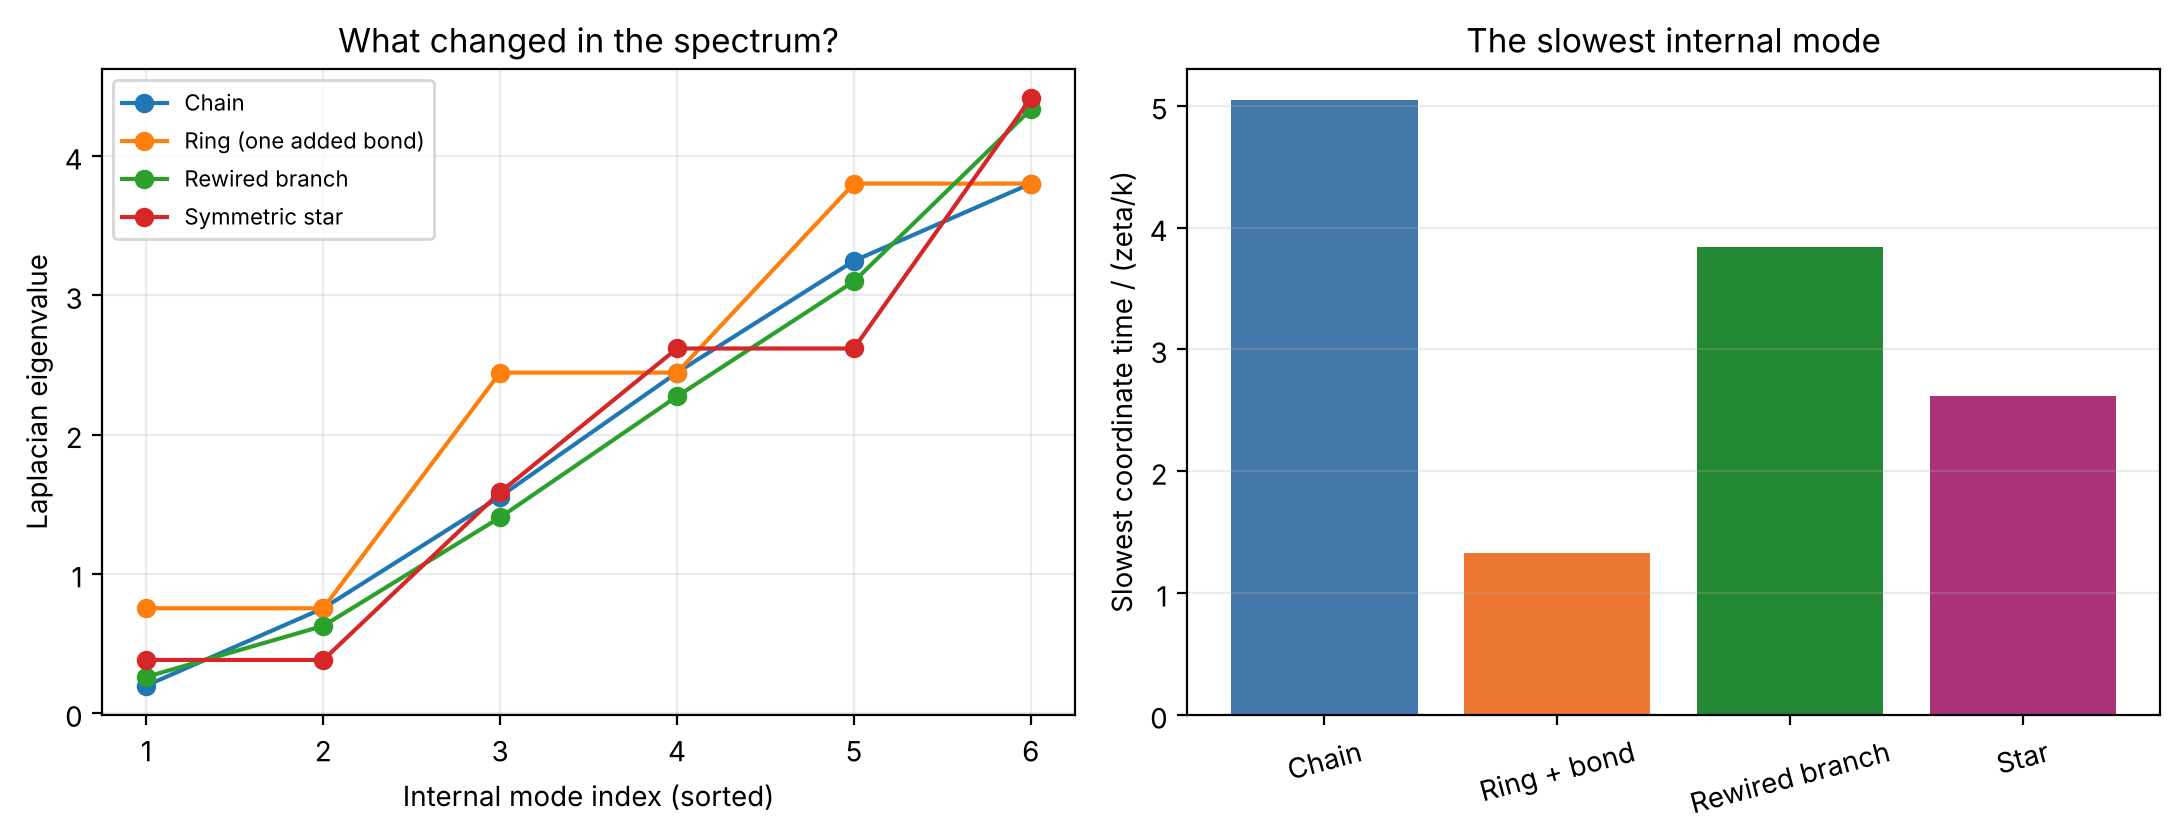

In [8]:
# Open a spectrum panel and a slow-time panel for the same four graphs.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
# Give each architecture its own positive-mode spectrum curve.
for name, eigenvalues in comparison_spectra.items():
    # Keep all six internal mode numbers in increasing-eigenvalue order.
    axes[0].plot(np.arange(1, bead_count), eigenvalues[1:], marker='o', label=name)
# Label the spectrum panel and distinguish the connected graphs.
axes[0].set(xlabel='Internal mode index (sorted)', ylabel='Laplacian eigenvalue', title='What changed in the spectrum?')
# Identify which curve represents the bond addition and the bond move.
axes[0].legend(fontsize=8)
# Add a light guide without obscuring coincident or degenerate eigenvalues.
axes[0].grid(alpha=0.25)
# Choose the same comparison order for bar labels and slow-time values.
comparison_names = list(comparison_spectra)
# Convert each smallest positive rate to its coordinate time.
comparison_times = [1.0 / comparison_spectra[name][1] for name in comparison_names]
# Draw one bar per topology rather than conflating different mode weights.
axes[1].bar(np.arange(len(comparison_names)), comparison_times, color=['#4477AA', '#EE7733', '#228833', '#AA3377'])
# Put short descriptions under their corresponding bars.
axes[1].set_xticks(np.arange(len(comparison_names)), ['Chain', 'Ring + bond', 'Rewired branch', 'Star'], rotation=15)
# Label the time as a coordinate mode time and include its scale.
axes[1].set(ylabel='Slowest coordinate time / (zeta/k)', title='The slowest internal mode')
# Add a horizontal guide to support rough comparisons between bars.
axes[1].grid(axis='y', alpha=0.25)
# Keep long spectrum labels and rotated bar labels within the figure.
fig.tight_layout()
# Display a direct before-and-after result for the changed connections.
plt.show()

**Connection-change checkpoint.** Closing this chain into a ring changes $\lambda_1$ from about 0.198 to 0.753 and the slowest **coordinate** time from about $5.05$ to $1.33$ in units of $\zeta/k$. Moving a bond to make the asymmetric branch preserves six springs and gives an intermediate slowest time of about $3.84$ for this particular rewire. The symmetric three-arm star gives about $2.62$. The full six-mode spectra also change, so one time alone does not describe the entire relaxation response. The ring comparison includes an extra spring; the chain-to-branch rewire isolates the effect of **arrangement at fixed edge count**.

### A size check: how longer chains change the slowest mode

For an open chain with $N$ beads, $\lambda_1=2[1-\cos(\pi/N)]$. For large $N$, this approaches $\pi^2/N^2$, so the slowest **coordinate** time in units of $\zeta/k$ approaches $N^2/\pi^2$. We can build several chains, calculate their smallest positive eigenvalue, and compare the exact finite-size times with the asymptotic formula. This is a fixed-parameter free-draining Rouse-model result, not a universal law for entangled polymers or for changing coarse-graining parameters.

N= 4: time*=   1.7071; large-N=   1.6211
N= 8: time*=   6.5685; large-N=   6.4846
N=16: time*=  26.0217; large-N=  25.9382
N=32: time*= 103.8363; large-N= 103.7529
N=64: time*= 415.0949; large-N= 415.0116


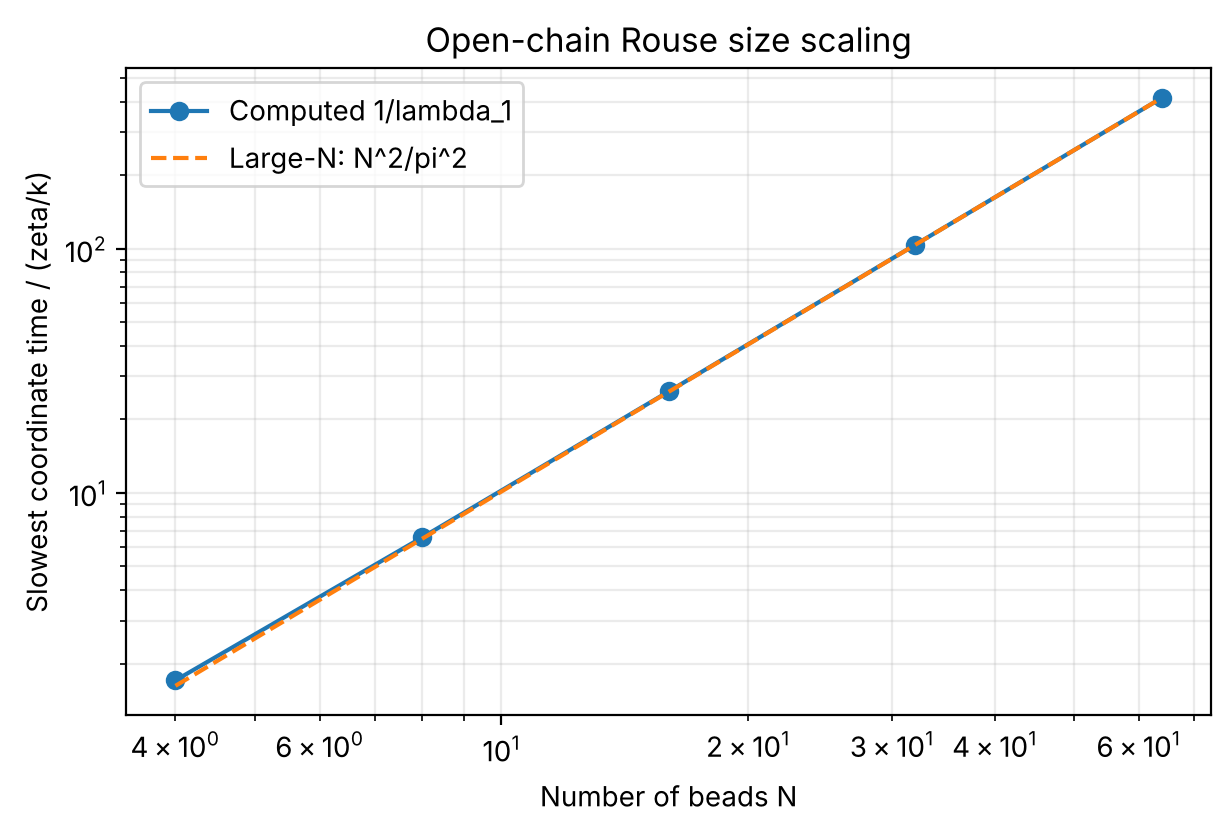

In [9]:
# Choose several bead counts to compare short chains with the large-N limit.
chain_sizes = [4, 8, 16, 32, 64]
# Prepare one dimensionless slow coordinate time for each chain size.
slow_chain_times = []
# Build a chain Laplacian and find its smallest positive eigenvalue at each size.
for size in chain_sizes:
    # Connect consecutive bead indices by one spring apiece.
    edges = [(index, index + 1) for index in range(size - 1)]
    # Extract the node Laplacian from the generic graph builder.
    laplacian = graph_matrices(size, edges)[3]
    # Exclude the first eigenvalue, which is the translation mode.
    first_internal = np.linalg.eigvalsh(laplacian)[1]
    # Convert its dimensionless decay rate to a coordinate time.
    slow_chain_times.append(1.0 / first_internal)
    # Check the numerical spectrum against the known open-chain formula.
    assert np.isclose(first_internal, 2.0 * (1.0 - np.cos(np.pi / size)), rtol=1e-11)
# Evaluate the large-N approximation on the same bead-count grid.
large_n_prediction = np.array(chain_sizes, dtype=float)**2 / np.pi**2
# Print exact numerical and asymptotic times so their discrepancy is visible.
for size, measured, asymptotic in zip(chain_sizes, slow_chain_times, large_n_prediction):
    # Keep both values dimensionless instead of implying physical seconds.
    print(f'N={size:2d}: time*={measured:9.4f}; large-N={asymptotic:9.4f}')
# Create a log-log figure for the chain-length experiment.
fig, ax = plt.subplots(figsize=(7, 4.2))
# Plot the reciprocal eigenvalues calculated from each graph matrix.
ax.loglog(chain_sizes, slow_chain_times, marker='o', label='Computed 1/lambda_1')
# Plot the asymptotic quadratic prediction separately.
ax.loglog(chain_sizes, large_n_prediction, linestyle='--', label='Large-N: N^2/pi^2')
# State bead count and time units rather than labelling this as measured rheology.
ax.set(xlabel='Number of beads N', ylabel='Slowest coordinate time / (zeta/k)', title='Open-chain Rouse size scaling')
# Add a subdued grid for following the trend across chain lengths.
ax.grid(True, which='both', alpha=0.25)
# Distinguish the finite calculation from its asymptotic approximation.
ax.legend()
# Display the size dependence next to the exact spectrum discussion.
plt.show()

**Size checkpoint.** Doubling $N$ approaches a fourfold increase in the slowest coordinate time as $N$ becomes large. At small $N$, use the exact trigonometric expression. Under the later ideal shear formula, the corresponding stress time is half the coordinate time for each mode.

**Checkpoint.** The ring's closing edge changes its spectrum; it does not create a second *node* zero mode. The star and chain each have six edges, yet their distributions of relaxation rates differ. The slowest mode is associated with $\lambda_1$, but individual bead responses also depend on how strongly the chosen initial displacement projects onto each eigenvector. We will test that dependence next.

## 4. Relax a small displacement: exact modes versus an Euler loop

Choose bead 6 displaced by one arbitrary unit while the other beads share a compensating displacement, so the center of mass remains at zero. For a given graph, decompose $u(0)$ into eigenmodes and evaluate $u(t^*)=V\,\mathrm{diag}(e^{-\lambda_pt^*})V^\mathsf Tu(0)$. This is exact for the deterministic **linear model** up to floating-point roundoff. Then use the first-year forward Euler rule $u_{n+1}=u_n-\Delta t^*Lu_n$ for the chain. Its finite time-step error should decrease when we halve the step. We compare against the exact modal calculation instead of assuming a smooth-looking numerical curve is correct.

The thermal Brownian force is omitted in this recovery experiment. The real equilibrium molecule continues fluctuating; these curves show the decay of a small deterministic disturbance or ensemble mean, not a frozen polymer returning to a unique conformation.

In [10]:
# Define the exact solution of the dimensionless deterministic model from eigenpairs.
def modal_displacement(initial, eigenvalues, eigenvectors, time_star):
    # Explain that output is a bead displacement vector at dimensionless time.
    """Return V*exp(-lambda*t*)*V.T*initial for one graph."""
    # Convert the input displacement to a floating-point vector.
    initial = np.asarray(initial, dtype=float)
    # Require dimensions compatible with a complete square eigenvector matrix.
    if initial.ndim != 1 or eigenvectors.shape != (len(initial), len(initial)) or len(eigenvalues) != len(initial):
        # Diagnose mismatched matrix and bead-array shapes.
        raise ValueError('initial and eigenpairs have incompatible sizes')
    # Reject negative or non-finite evaluation time.
    if not np.isfinite(time_star) or time_star < 0.0:
        # Keep this demonstration on the physical time domain.
        raise ValueError('time_star must be nonnegative and finite')
    # Project the initial bead coordinates onto all orthonormal eigenvectors.
    modal_amplitudes = eigenvectors.T @ initial
    # Decay each amplitude at its own Laplacian eigenvalue.
    decayed_amplitudes = np.exp(-eigenvalues * time_star) * modal_amplitudes
    # Reconstruct bead coordinates from the decayed normal modes.
    return eigenvectors @ decayed_amplitudes

# Set an initial displacement with bead 6 higher than the average.
initial_shape = np.zeros(bead_count)
# Give the final bead one arbitrary displacement unit.
initial_shape[6] = 1.0
# Remove the average so the translation mode cannot dominate the picture.
initial_shape -= initial_shape.mean()
# Choose a time grid in units of the characteristic scale zeta/k.
times_star = np.linspace(0.0, 12.0, 241)
# Compute one normalized displacement magnitude for every graph and time.
recovery_norms = {}
# Visit each topology with the same bead-index perturbation.
for name, (eigenvalues, eigenvectors) in spectra.items():
    # Save the Euclidean norm of the exact recovered bead-coordinate vector.
    recovery_norms[name] = [np.linalg.norm(modal_displacement(initial_shape, eigenvalues, eigenvectors, float(t))) for t in times_star]
    # Check the exact modal solution reproduces the prescribed start.
    assert np.allclose(modal_displacement(initial_shape, eigenvalues, eigenvectors, 0.0), initial_shape)
# Confirm all three center-of-mass coordinates remain zero in this model.
assert np.isclose(initial_shape.sum(), 0.0)

In [11]:
# Define an explicit Euler integrator for the dimensionless displacement equation.
def euler_recovery(initial, laplacian, time_step, steps):
    # State that the method returns one bead vector after the requested work.
    """Perform steps of u <- u - time_step*L*u."""
    # Copy the input so the caller's displacement remains available for checks.
    current = np.array(initial, dtype=float, copy=True)
    # Require a positive finite step and a nonnegative integer loop count.
    if not np.isfinite(time_step) or time_step <= 0.0 or isinstance(steps, bool) or not isinstance(steps, int) or steps < 0:
        # Explain the bounded time-stepping requirements.
        raise ValueError('time_step must be positive and steps nonnegative integer')
    # Advance exactly the requested number of equal Euler steps.
    for step in range(steps):
        # Calculate spring-driven change from the current bead displacement.
        current = current - time_step * (laplacian @ current)
    # Return the resulting vector for comparison with the modal solution.
    return current

# Fix a final comparison time that both proposed step sizes divide exactly.
comparison_time = 3.0
# Compute the exact chain displacement from the spectral formula at that time.
chain_exact_at_three = modal_displacement(initial_shape, *spectra['Chain'], comparison_time)
# Integrate sixty steps of width 0.05 to the same dimensionless time.
chain_euler_coarse = euler_recovery(initial_shape, chain_L, 0.05, 60)
# Integrate twice as many steps of half the width to the same final time.
chain_euler_fine = euler_recovery(initial_shape, chain_L, 0.025, 120)
# Measure both vector errors against the independent exact solution.
coarse_error = np.linalg.norm(chain_euler_coarse - chain_exact_at_three)
# Measure the refined Euler error in the same Euclidean norm.
fine_error = np.linalg.norm(chain_euler_fine - chain_exact_at_three)
# Print both errors rather than claiming an untested convergence rate.
print(f'Euler displacement error at t*=3: step 0.05 -> {coarse_error:.6e}; step 0.025 -> {fine_error:.6e}')
# Confirm the refined step improved the numerical result for this example.
assert fine_error < coarse_error
# Check that the chain's numerical mean remains essentially zero.
assert abs(chain_euler_fine.sum()) < 1e-12

Euler displacement error at t*=3: step 0.05 -> 2.410740e-03; step 0.025 -> 1.205384e-03


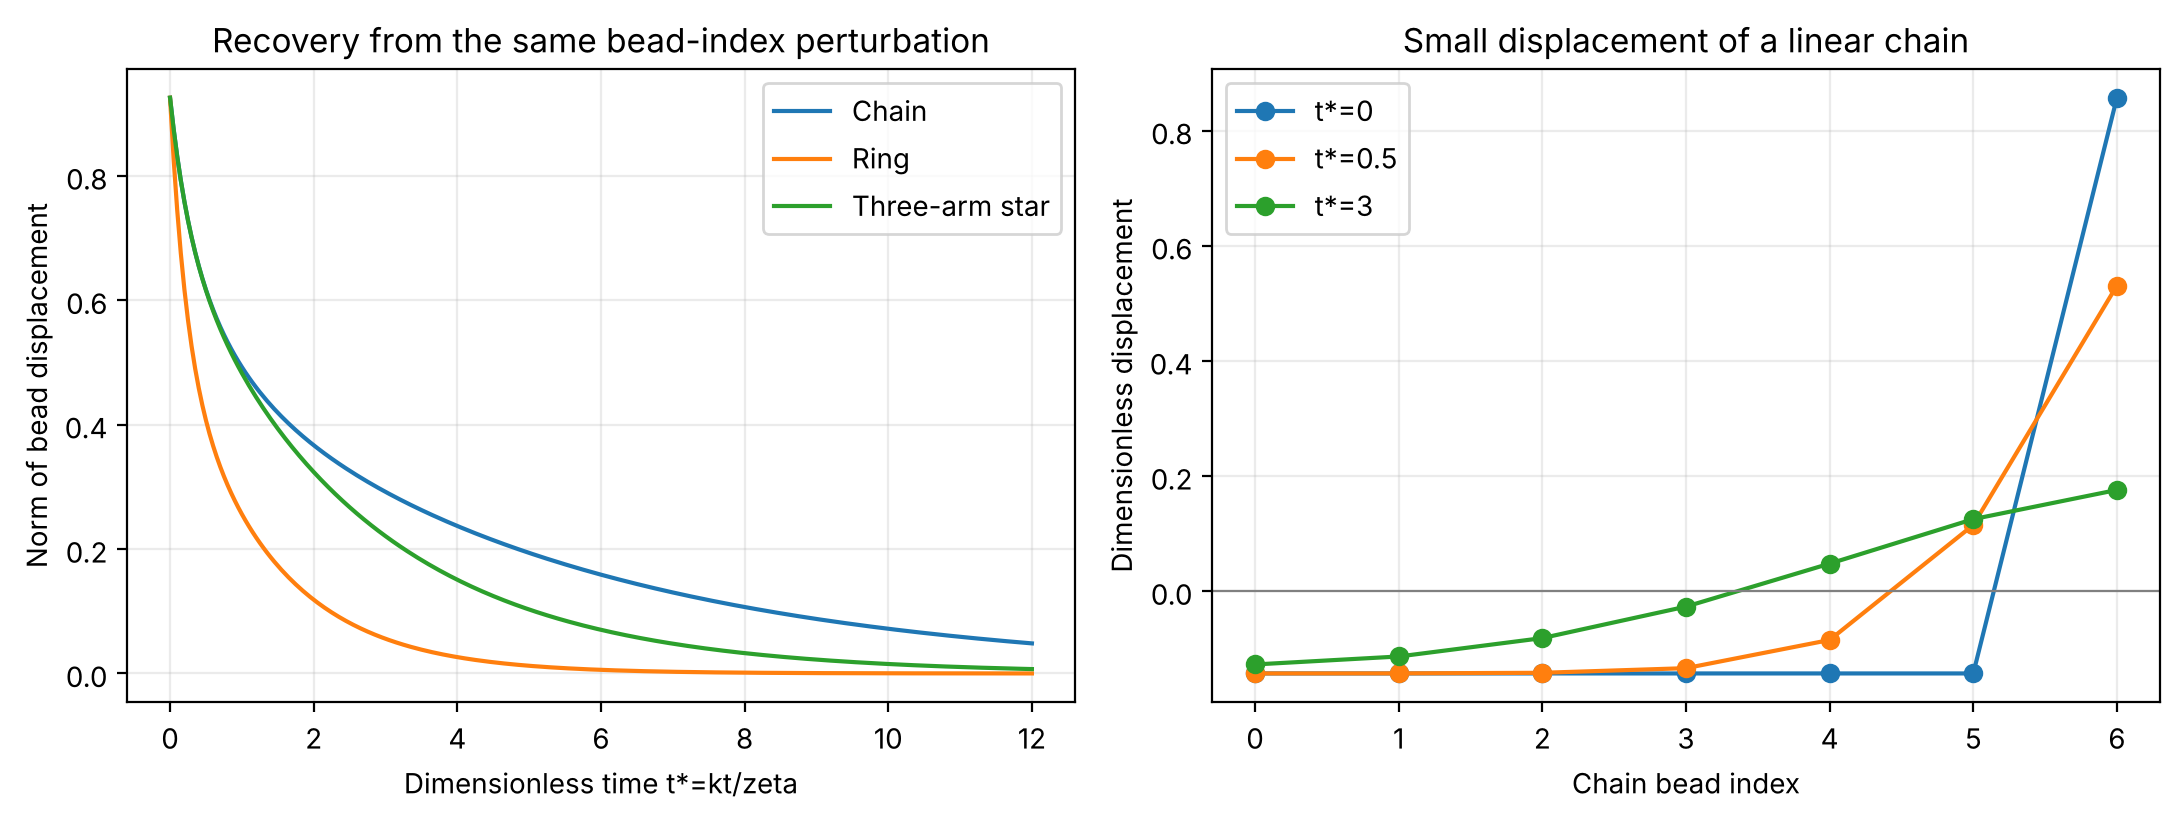

In [12]:
# Create one panel for relaxation norms and another for the chain's shape over time.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
# Plot the disturbance norm for each topology from exact modal evolution.
for name, norms in recovery_norms.items():
    # Label each topology so the initial-coordinate choice can be interpreted.
    axes[0].plot(times_star, norms, label=name)
# Make the time scaling and magnitude explicit.
axes[0].set(xlabel='Dimensionless time t*=kt/zeta', ylabel='Norm of bead displacement', title='Recovery from the same bead-index perturbation')
# Identify the three topology curves without implying a stress response.
axes[0].legend()
# Plot the chain bead displacements at three selected times.
for moment in (0.0, 0.5, 3.0):
    # Reconstruct one chain displacement vector at the chosen time.
    shape = modal_displacement(initial_shape, *spectra['Chain'], moment)
    # Show how the disturbance spreads and relaxes along bead indices.
    axes[1].plot(np.arange(bead_count), shape, marker='o', label=f't*={moment:g}')
# Label the deterministic coordinate response, not a viscoelastic modulus.
axes[1].set(xlabel='Chain bead index', ylabel='Dimensionless displacement', title='Small displacement of a linear chain')
# Mark the undeformed average line for visual reference.
axes[1].axhline(0.0, color='gray', linewidth=0.8)
# Label each comparison time in the chain panel.
axes[1].legend()
# Add light grids to both trajectory plots.
for ax in axes:
    # Use subdued grids that do not dominate the data curves.
    ax.grid(alpha=0.25)
# Keep titles and axes clear at notebook display width.
fig.tight_layout()
# Render the exact mode evolution beside a bead-level picture.
plt.show()

**Checkpoint.** A bead-coordinate norm after a particular perturbation is **not** a relaxation modulus. It depends on the initial displacement's projection onto the modes. The spectrum itself does not depend on that displacement. Halving the Euler step reduced error for the chosen final time, which tests a programming approximation against the exact linear solution. A large Euler step can be unstable even though the physical overdamped model is stable.

## 5. Optional rheology: from mode spectrum to shear relaxation

The cited bead-spring theory relates normal modes to **linear viscoelastic** response. After a small step shear, the Hookean spring stress depends on second moments of bead displacements. Each internal coordinate factor decays at rate $\lambda_p$ in $t^*$, so the ideal shear-stress contribution decays at rate **$2\lambda_p$**. For one connected molecule with equal bead friction and equal Hookean springs, and with a common mode weight under this idealization,

$$G(t)=c k_{\rm B}T\sum_{p=1}^{N-1}e^{-2\lambda_p t^*},\qquad t^*=kt/\zeta.$$

Here $c$ is the **number density of modeled molecules**, and $k_{\rm B}T$ is thermal energy. The translation mode is excluded; for every connected graph here, $G(0)=c k_{\rm B}T(N-1)$. We plot $g(t^*)=G(t)/G(0)$ to avoid pretending that an arbitrary spring constant or bead friction has been measured. Then $\tau_p^{\rm stress}/(\zeta/k)=1/(2\lambda_p)$, while the coordinate time is $1/\lambda_p$. This factor of two is a physical observable distinction, not a discrepancy between eigenvalue algorithms.

The comparison keeps **bead count, per-spring $k$, and per-bead $\zeta$** fixed. Ring closure adds an edge. A real ring, branched melt, or entangled network may require hydrodynamic, entanglement, and topological constraints beyond this ideal free-draining Gaussian description. We use the formula as a model demonstration, not as a universal rheological law.

In [13]:
# Define the normalized ideal shear relaxation function for one connected graph.
def normalized_modulus(eigenvalues, time_star):
    # Explain that only positive internal modes contribute to G/G(0).
    """Return mean(exp(-2*lambda_p*t*)) over nonzero modes."""
    # Convert a scalar or array of time values to an ndarray for vectorization.
    times = np.asarray(time_star, dtype=float)
    # Reject times outside the nonnegative finite time domain.
    if not np.all(np.isfinite(times)) or np.any(times < 0.0):
        # Keep the relaxation curve interpretable as elapsed time.
        raise ValueError('times must be finite and nonnegative')
    # Exclude the sorted first eigenvalue, which represents translation.
    internal = np.asarray(eigenvalues[1:], dtype=float)
    # Require at least one positive mode for a normalized polymer response.
    if len(internal) == 0 or np.any(internal <= 0.0):
        # Distinguish a connected nontrivial graph from an invalid mode list.
        raise ValueError('provide a connected graph with positive internal modes')
    # Average mode responses so all our seven-bead examples start at one.
    return np.mean(np.exp(-2.0 * internal[:, None] * np.atleast_1d(times)[None, :]), axis=0)

# Make a time grid that displays both rapid early and slow late relaxation.
modulus_times = np.linspace(0.0, 12.0, 241)
# Store normalized shear relaxation for every architecture.
relaxation_curves = {}
# Evaluate the model spectrum without using bead-coordinate initial conditions.
for name, (eigenvalues, eigenvectors) in spectra.items():
    # Calculate the mean over exactly six internal stress modes.
    relaxation_curves[name] = normalized_modulus(eigenvalues, modulus_times)
    # Verify that normalization produces a unit initial modulus for each graph.
    assert np.isclose(relaxation_curves[name][0], 1.0)
    # Confirm the finite-time response remains nonnegative and nonincreasing.
    assert np.all(relaxation_curves[name] >= 0.0) and np.all(np.diff(relaxation_curves[name]) <= 1e-12)

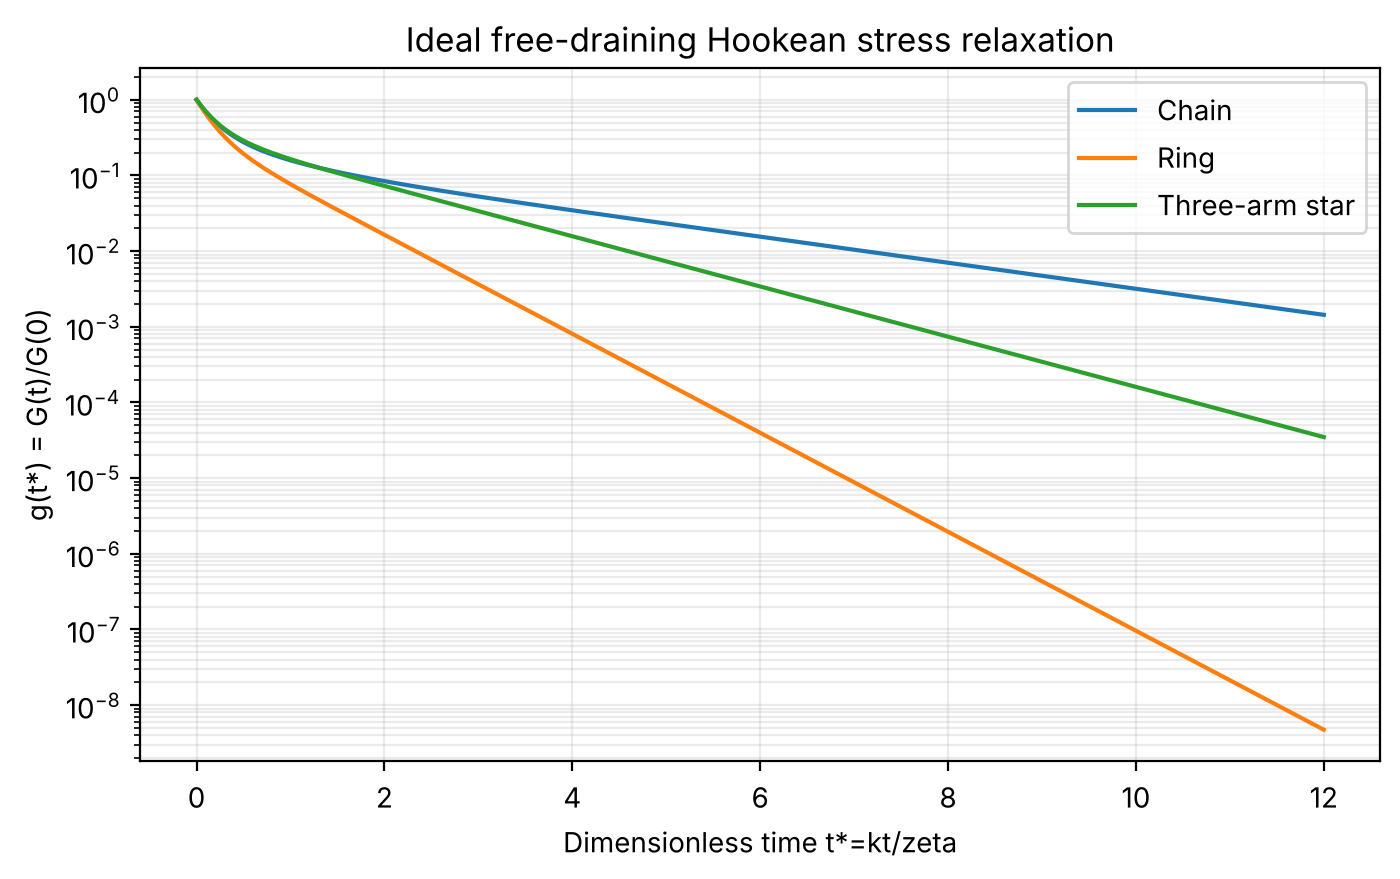

In [14]:
# Draw the ideal model relaxation functions from the three graph spectra.
fig, ax = plt.subplots(figsize=(8, 4.5))
# Plot each normalized response from the same time grid and bead count.
for name, response in relaxation_curves.items():
    # Use the topology name rather than a fitted physical material label.
    ax.plot(modulus_times, response, label=name)
# Label dimensionless time and the normalized shear relaxation modulus.
ax.set(xlabel='Dimensionless time t*=kt/zeta', ylabel='g(t*) = G(t)/G(0)', title='Ideal free-draining Hookean stress relaxation')
# Add a log scale to reveal the slow internal modes without changing data.
ax.set_yscale('log')
# Give a faint guide and identify all three topology curves.
ax.grid(True, which='both', alpha=0.25)
# Keep the topology labels visible over the full plot range.
ax.legend()
# Display the stress response separately from the earlier displacement figure.
plt.show()

### An independent frequency-domain check

For a generalized Maxwell sum with **equal idealized mode weights**, define $\tau_p^*=1/(2\lambda_p)$ and dimensionless angular frequency $\omega^*=\omega\zeta/k$. Dividing the moduli by $G(0)=c k_{\rm B}T(N-1)$ gives

$$g'(\omega^*)=\frac1{N-1}\sum_{p=1}^{N-1}\frac{(\omega^*\tau_p^*)^2}{1+(\omega^*\tau_p^*)^2},\qquad
g''(\omega^*)=\frac1{N-1}\sum_{p=1}^{N-1}\frac{\omega^*\tau_p^*}{1+(\omega^*\tau_p^*)^2}.$$

The dimensionless **zero-frequency viscosity measure** is $\eta/(G(0)\zeta/k)=\int_0^\infty g(t^*)\,dt^*=\frac1{N-1}\sum_p\tau_p^*$. We can check its frequency-domain counterpart $\lim_{\omega^*\to0}g''/\omega^*$ numerically. This is a useful cross-check from a different representation of the same ideal model, not an experimental viscosity prediction.

In [15]:
# Define the normalized storage and loss moduli of the ideal mode sum.
def dynamic_moduli(eigenvalues, frequencies_star):
    # State that the output arrays are g-prime and g-double-prime.
    """Return normalized G' and G'' at positive dimensionless frequencies."""
    # Convert frequency input to a one-dimensional numeric array.
    frequencies = np.asarray(frequencies_star, dtype=float)
    # Require positive finite frequency values for log-scale plots.
    if frequencies.ndim != 1 or not np.all(np.isfinite(frequencies)) or np.any(frequencies <= 0.0):
        # Explain the input needed for this frequency-domain example.
        raise ValueError('frequencies must be a one-dimensional positive array')
    # Convert positive internal graph eigenvalues to dimensionless stress times.
    stress_times = 1.0 / (2.0 * np.asarray(eigenvalues[1:], dtype=float))
    # Form every mode-frequency product in a two-dimensional array.
    products = stress_times[:, None] * frequencies[None, :]
    # Average the standard Maxwell storage contributions across all internal modes.
    storage = np.mean(products**2 / (1.0 + products**2), axis=0)
    # Average the corresponding Maxwell loss contributions on the same grid.
    loss = np.mean(products / (1.0 + products**2), axis=0)
    # Return both dimensionless moduli for comparison and plotting.
    return storage, loss

# Span frequencies well below and above the slowest modes in dimensionless units.
frequency_grid = np.logspace(-3.0, 2.0, 300)
# Calculate both moduli for the three topology examples.
dynamic_curves = {name: dynamic_moduli(values, frequency_grid) for name, (values, vectors) in spectra.items()}
# Compare a direct mode sum for viscosity with a low-frequency loss limit.
for name, (values, vectors) in spectra.items():
    # Integrate each exponential analytically to form the dimensionless viscosity.
    viscosity_measure = np.mean(1.0 / (2.0 * values[1:]))
    # Estimate the same low-frequency limit using the first grid point.
    low_frequency_estimate = dynamic_curves[name][1][0] / frequency_grid[0]
    # Display both values and identify this as a finite-frequency approximation.
    print(f'{name:15s}: integral viscosity measure={viscosity_measure:.6f}; g"/omega* at {frequency_grid[0]:g}={low_frequency_estimate:.6f}')
    # Check the low-frequency numerical estimate is close for this grid.
    assert np.isclose(low_frequency_estimate, viscosity_measure, rtol=1e-4)

Chain          : integral viscosity measure=0.666667; g"/omega* at 0.001=0.666664
Ring           : integral viscosity measure=0.333333; g"/omega* at 0.001=0.333333
Three-arm star : integral viscosity measure=0.571429; g"/omega* at 0.001=0.571428


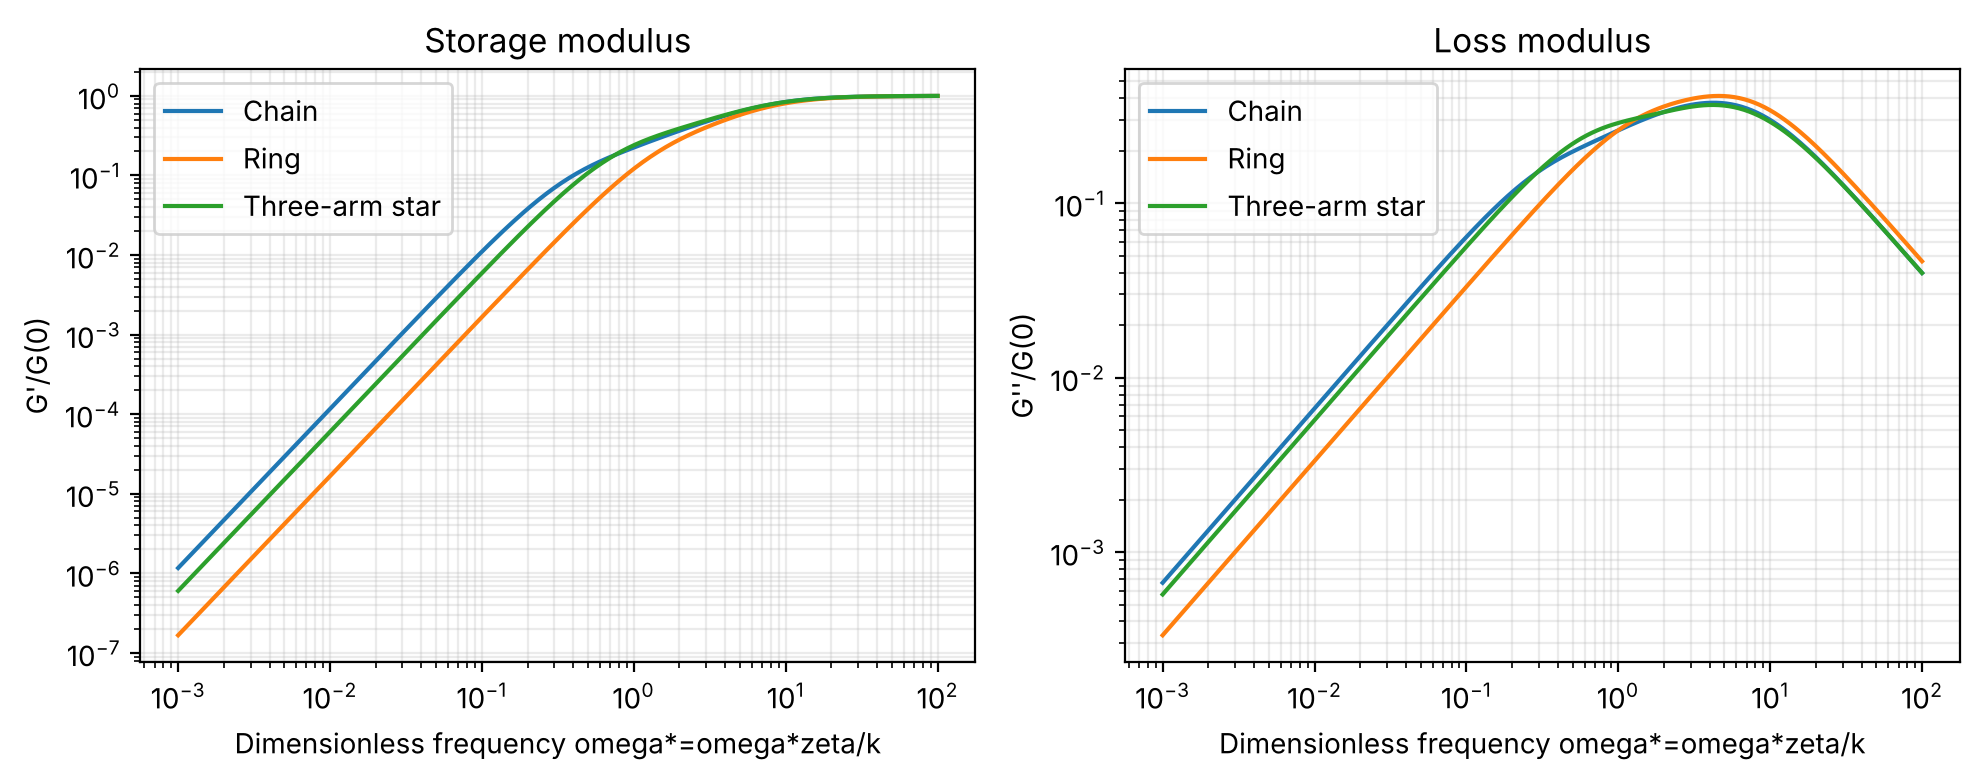

In [16]:
# Create separate panels for normalized elastic storage and viscous loss.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# Visit each topology and its calculated dynamic modulus pair.
for name, (storage, loss) in dynamic_curves.items():
    # Plot normalized storage modulus against dimensionless angular frequency.
    axes[0].loglog(frequency_grid, storage, label=name)
    # Plot normalized loss modulus on its own vertical scale.
    axes[1].loglog(frequency_grid, loss, label=name)
# Label both physical response concepts and their normalized units.
axes[0].set(xlabel='Dimensionless frequency omega*=omega*zeta/k', ylabel="G'/G(0)", title='Storage modulus')
# Give the loss panel the same horizontal meaning without merging responses.
axes[1].set(xlabel='Dimensionless frequency omega*=omega*zeta/k', ylabel="G''/G(0)", title='Loss modulus')
# Add a light guide and topology labels to both panels.
for ax in axes:
    # Draw unobtrusive major and minor grid lines on the logarithmic plots.
    ax.grid(True, which='both', alpha=0.25)
    # Identify the chain, ring, and star curves in each panel.
    ax.legend()
# Adjust layout to avoid clipping labels and titles in the notebook.
fig.tight_layout()
# Display frequency-domain predictions of this idealized relaxation spectrum.
plt.show()

**Interpretation.** The modes and spring/friction scales determine the idealized time and frequency responses. A change in graph connectivity can redistribute the response over relaxation times. Our ring has one **additional spring** relative to the chain, whereas the star and chain have equal numbers of springs but different arrangements. At high dimensionless frequency the normalized storage sum tends to one, while the loss sum eventually decreases; at low frequency $g''/\omega^*$ approaches the integrated relaxation measure. These are consequences of the chosen equal-spring Rouse model.

## 6. Optional graph theory: an extra zero mode in edge space

Our $N\times N$ **node** Laplacian $L=BB^\mathsf T$ has one zero translation eigenvalue for any connected graph. The $m\times m$ **edge-space** matrix $R=B^\mathsf TB$ has the same **nonzero** eigenvalues, but can have extra zeros when $m>N-1$. The chain and three-arm star are trees with $m=N-1$, so their edge-space matrices have no zero mode. The ring has $m=N$, so it has one edge-space zero vector: an oriented circulation around its closed cycle satisfies $Bc=0$. This is **not** a second translation mode of the beads.

An arbitrary incidence-column direction changes signs in $B$ and the coordinates of that cycle vector; it does not change the node Laplacian or its nonzero spectrum. This is analogous to circulation bookkeeping in the Hardy Cross pipe-network notebook, but there the loop variable was a flow correction, whereas here it identifies a linear dependence among ring connector vectors. These are distinct physical problems that share a graph-theoretic structure.

In [17]:
# Extract the chain incidence matrix with six edge columns.
chain_incidence = matrices['Chain'][2]
# Extract the ring incidence matrix with seven edge columns.
ring_incidence = matrices['Ring'][2]
# Construct the chain's six-by-six edge-space matrix.
chain_edge_matrix = chain_incidence.T @ chain_incidence
# Construct the ring's seven-by-seven edge-space matrix.
ring_edge_matrix = ring_incidence.T @ ring_incidence
# Sort their eigenvalues using the symmetric eigensolver.
chain_edge_eigenvalues = np.linalg.eigvalsh(chain_edge_matrix)
# Resolve the ring edge-space spectrum in the same way.
ring_edge_eigenvalues = np.linalg.eigvalsh(ring_edge_matrix)
# Define a circulation following the oriented chain edges and closing edge.
ring_circulation = np.ones(len(ring_edges))
# Check that the oriented spring sequence returns to its initial node.
assert np.allclose(ring_incidence @ ring_circulation, 0.0)
# Verify that this cycle vector is a zero mode of the edge-space matrix.
assert np.allclose(ring_edge_matrix @ ring_circulation, 0.0)
# Show the dimension difference and number of numerical zeros explicitly.
print(f'Chain: B shape={chain_incidence.shape}; edge-space zeros={np.count_nonzero(np.abs(chain_edge_eigenvalues)<1e-10)}')
# Report one additional edge-space zero for the cyclic structure.
print(f'Ring:  B shape={ring_incidence.shape}; edge-space zeros={np.count_nonzero(np.abs(ring_edge_eigenvalues)<1e-10)}')
# Check that the ring's six positive edge eigenvalues match its node modes.
assert np.allclose(ring_edge_eigenvalues[1:], spectra['Ring'][0][1:], atol=1e-12)
# Check that the tree's six edge eigenvalues match all six node internal modes.
assert np.allclose(chain_edge_eigenvalues, spectra['Chain'][0][1:], atol=1e-12)

Chain: B shape=(7, 6); edge-space zeros=0
Ring:  B shape=(7, 7); edge-space zeros=1


## 7. Model checks, common mistakes, and extensions

| Check | What it establishes for the code | What it does not establish |
|:--|:--|:--|
| $L=L^\mathsf T=BB^\mathsf T$ and $L\mathbf1=0$ | Correct matrix construction and translational null mode | Correct spring/friction data for a real polymer |
| Six positive internal eigenvalues | Each seven-bead example is connected in this construction | That a ring's edge-space matrix has no extra zero |
| Chain and ring analytic spectra | Numerical eigenvalues agree with independent formulas | Validity of the ideal model for entangled melts |
| Euler refinement against modes | The chosen numerical integration improves | General stability for arbitrary step sizes |
| $g(0)=1$ and low-frequency viscosity check | Consistency between mode sum and Maxwell formulas | Measured storage/loss moduli |

**Common pitfalls.** (1) Do not call the graph drawing a molecular conformation. (2) Do not equate the coordinate decay time $1/\lambda$ with the ideal stress decay time $1/(2\lambda)$. (3) A ring is still connected and has only one zero **node** eigenvalue; its extra edge-space zero comes from a cycle. (4) Individual eigenvectors may change signs, and degenerate ring eigenvectors may rotate within their common eigenspace. (5) The Rouse model's free-draining assumptions do not represent hydrodynamic interactions, entanglements, and nonlinear deformation.

### Exercises to attempt before the answer cell

1. Draw a four-bead chain by hand. Write its adjacency, degree, and Laplacian matrices. Check each row sum.
2. Add edge $(3,0)$ to make a four-bead ring. How many edges and positive **node** eigenvalues should it have?
3. Use $u=(1,1,1,1)$ and $u=(1,-1,0,0)$ for the four-bead chain. Which displacement costs no spring energy? Why?
4. In the seven-bead examples, compare the smallest positive eigenvalues. Which **internal coordinate** time is longest in our equal-$k$, equal-$\zeta$ model?
5. If one internal eigenvalue is $\lambda=0.5$, give the coordinate and ideal shear-stress times in units of $\zeta/k$. Explain their factor of two.
6. Halve the Euler step again at the same final time and compare its error. Does the result match the trend observed above?
7. Optional: delete the closing ring edge. Verify that the edge-space cycle zero mode disappears but the single node translation zero remains.
8. Optional: add a spring between chain beads 1 and 5. Check the new Laplacian's row sums and observe which internal eigenvalues change. What model parameter besides graph topology was changed by adding that spring?
9. In the focused experiment, why is chain-to-ring an **added bond** comparison, whereas chain-to-rewired-branch is a **fixed spring count** comparison? Which change decreased the slowest coordinate time in this example?


In [18]:
# Build a four-bead chain for the first exercise independently of the main graph.
small_edges = [(0, 1), (1, 2), (2, 3)]
# Obtain all four matrix objects from the same reusable graph builder.
small_A, small_D, small_B, small_L = graph_matrices(4, small_edges)
# Make a four-bead ring by adding exactly one closing spring.
small_ring = graph_matrices(4, small_edges + [(3, 0)])
# Print the chain Laplacian so the hand calculation can be compared.
print('Four-bead chain Laplacian:\n', small_L.astype(int))
# Evaluate the uniform translation energy for exercise three.
uniform_energy = np.ones(4) @ small_L @ np.ones(4)
# Evaluate the nonuniform bead-displacement energy in the same graph.
nonuniform = np.array([1.0, -1.0, 0.0, 0.0])
# Use a quadratic form to compare the second displacement with translation.
nonuniform_energy = nonuniform @ small_L @ nonuniform
# Show the two energies up to the common k/2 energy factor.
print(f'Quadratic forms: uniform={uniform_energy:.1f}, nonuniform={nonuniform_energy:.1f}')
# Report the coordinate and stress times for a single sample eigenvalue.
print('At lambda=0.5: coordinate time*=2.0, stress time*=1.0')
# Verify the four-bead ring has one zero and three positive node modes.
assert np.count_nonzero(np.abs(np.linalg.eigvalsh(small_ring[3])) < 1e-10) == 1
# Verify that uniform translation costs zero but a nonuniform deformation does not.
assert np.isclose(uniform_energy, 0.0) and nonuniform_energy > 0.0

Four-bead chain Laplacian:
 [[ 1 -1  0  0]
 [-1  2 -1  0]
 [ 0 -1  2 -1]
 [ 0  0 -1  1]]
Quadratic forms: uniform=0.0, nonuniform=5.0
At lambda=0.5: coordinate time*=2.0, stress time*=1.0


**Answer interpretations.** (1) The chain Laplacian has end diagonals 1, interior diagonals 2, and $-1$ between neighbors; all row sums vanish. (2) The four-bead ring has four edges and three positive node eigenvalues, plus one translation zero. (3) Uniform translation changes no spring length; the nonuniform vector changes at least one bead difference. (4) Read the smallest positive eigenvalues printed in Section 3; the smallest corresponds to the longest coordinate time. (5) The times are 2 and 1 in units of $\zeta/k$ respectively: stress involves a second moment. (6) Compare the new numerical error with the 0.05 and 0.025 results before inferring a trend. (7) Removing the closing edge makes a tree and eliminates the edge-space cycle null vector. (8) A new spring changes connectivity **and the total number of springs**, even if each spring retains the same stiffness.

(9) Ring closure adds a seventh spring, whereas the branch example removes one spring and attaches a new one, retaining six. Both lower the slowest coordinate time in this specified model, but the detailed spectra and the physical changes differ.

### Further reading

- Yuliang Yang and Tongyin Yu, *Graph theory of viscoelasticity of polymers with linear and cyclic chains*, **Makromol. Chem., Rapid Commun. 5**, 1–9 (1984). Motivates the chain/ring graph spectrum and incidence construction.
- Yuliang Yang and Tongyin Yu, *Graph theory of viscoelasticities for polymers with star-shaped, multiple-ring and cyclic multiple-ring molecules*, **Makromol. Chem. 186**, 609–631 (1985). Extends the topological treatment to branching and more complicated cycles and relates modes to rheological functions.
- Yuliang Yang, *Graph theory of viscoelastic and configurational properties of Gaussian chains*, **Macromol. Theory Simul. 7**, 521–549 (1998). A broad synthesis of graph spectra, Gaussian-chain configurations, and idealized viscoelastic properties.

These references treat substantially more advanced mathematics than this first-year notebook. Their notation and theoretical scope should be read in the original papers when pursuing rigorous rheology or graph-polynomial methods.

### Conclusion

A bead-spring graph gives a concrete route from **connectivity** to a Laplacian, from its eigenvalues to **internal relaxation times**, and, under stated thermal and free-draining assumptions, to an idealized **linear viscoelastic spectrum**. Python makes each stage inspectable: edge lists produce matrices, matrix checks protect against indexing errors, modal solutions check time stepping, and time- and frequency-domain expressions check one another. The model is a tool for reasoning about architecture; its assumptions must be revisited before comparing with measured polymers.